# Lean-13g : Maps PPT et la borne 2(d−1) — OQP 38

**Navigation** : [<< Lean-13f Corrélation Bell du vide](Lean-13f-Correlation-Bell-Vide-Lean-Python.ipynb) | [Index](README.md) | [Lean-17a Noeuds >>](KNOTS/KNOTS-01-Conway-Proofs-Lean-Python.ipynb)

**Kernel** : Python 3 (numérique et lecture des sources du lake `conway_lean`)

***

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. Manipuler la **transposition partielle** et le critère de Peres, et distinguer un *opérateur* PPT d'une *application* (map) PPT — complètement positive **et** complètement copositive.
2. Définir les applications **entanglement breaking** (EB) via la correspondance de Choi–Jamiołkowski : EB équivaut à une matrice de Choi séparable.
3. Expliquer l'histoire du problème OQP 38 : la **conjecture PPT²** (le carré d'une map PPT est-il EB ?), réfutée en septembre 2026, et la **borne 2(d−1)** qui la remplace (Turturean-Bao 2026).
4. Mesurer sur une famille jouet — les maps de Werner–Holevo $\Phi(X) = \alpha X + \beta X^T + \gamma\,\mathrm{Tr}(X)\,I$ — la fenêtre PPT, la loi de composition, et pourquoi le cas $d=2$ est dégénéré (PPT $\Rightarrow$ EB).
5. Lire le statut de la formalisation Lean 4 amont (treize énoncés de `Challenge.lean`, comparateur d'axiomes) et le relier à ce que couvre notre dépôt.

## Introduction

Le carnet [13f](Lean-13f-Correlation-Bell-Vide-Lean-Python.ipynb) a suivi une frontière d'**états** : quand la corrélation de Bell du vide retombe-t-elle au niveau classique ? Ce carnet suit une frontière de **canaux** : quand une opération quantique détruit-elle *tout* intrication, quel que soit ce qu'on lui fait subir ? Les deux questions sont parentes — l'intrication y est la ressource, et la frontière sépare ce qui la transmet de ce qui la casse.

L'histoire tient en trois temps :
1. **La conjecture.** Si une application linéaire $\Phi$ sur les matrices $d \times d$ est PPT (préserve la positivité même après transposition partielle sur un système témoin), alors composer $\Phi$ avec elle-même détruit-il toute intrication ? Sous forme de maps, la conjecture de Christandl (Christandl, Müller-Hermes, Wolf 2019) dit : **la composition de deux maps PPT quelconques est EB**.
2. **La réfutation.** Un preprint OpenAI du 27 septembre 2026 donne deux maps PPT sur des matrices $10 \times 10$ dont la composition n'est **pas** EB, et un canal PPT trace-préservant sur $21 \times 21$ dont le carré ne l'est pas *(rapporté par l'énoncé amont, non re-vérifié ici)*.
3. **La borne.** Turturean et Bao (2026) sauvent une version quantitative : $2(d-1)$ maps PPT — quelconques, différentes à chaque étape, trace-préservantes ou non — composent toujours en EB. C'est ce résultat que digère ce carnet.

## 1. La quantité centrale : quand un canal casse-t-il toute intrication ?

Une **application (map) quantique** $\Phi : M_d \to M_d$ agit sur les opérateurs. Trois propriétés
la classent sur une échelle de « brutalité » :

- $\Phi$ est **complètement positive** (CP) : $\mathrm{id}_k \otimes \Phi$ envoie tout opérateur
  positif sur un opérateur positif, pour toute dimension $k$ de système témoin — c'est la classe
  physiquement réalisable des canaux.
- $\Phi$ est **PPT** : CP **et** complètement copositive ($t \circ \Phi$ est CP, où $t$ est la
  transposition). Une map PPT peut transmettre de l'intrication, mais elle est « douce » avec la
  transposition partielle.
- $\Phi$ est **entanglement breaking** (EB) : $\mathrm{id}_k \otimes \Phi$ rend **séparable** tout
  opérateur positif entrant. Un canal EB est mesure puis re-préparation : une sortie
  **classique**. Il ne transmet **aucune** intrication, fût-elle déjà présente à l'entrée.

L'échelle est stricte dès que la dimension le permet : EB $\Rightarrow$ PPT $\Rightarrow$ CP ;
l'identité est CP non PPT en toute dimension (son Choi est $|\Omega\rangle\langle\Omega|$, de
transposée partielle $F$ non positive), et EB $\neq$ PPT dès $d \geq 3$ — à $d = 2$, au
contraire, EB et PPT **coïncident** (section 5.1). La question du OQP 38 est : **à quel rythme la composition
pousse-t-elle une map PPT vers EB ?** La conjecture répondait « dès deux » ; la réfutation dit
« deux ne suffisent pas en général » ; le théorème répond « $2(d-1)$ suffisent toujours ».

In [1]:
import sys
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("matplotlib  :", matplotlib.__version__)

# Le module d'utilitaires de la serie (meme outillage que Lean-13e/13f).
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import lean_notebook_utils as lnu
print("lean_notebook_utils : importe")

Python      : 3.13.16
numpy       : 2.2.6
scipy       : 1.18.1
matplotlib  : 3.11.2
lean_notebook_utils : importe


## 2. Le vocabulaire minimal : transposition partielle, Peres, Choi

**Opérateur PPT (critère de Peres).** Pour un opérateur hermitien $X$ positif sur
$\mathbb{C}^d \otimes \mathbb{C}^d$, la transposition partielle $X^\Gamma$ (transposer le second
facteur seulement) est encore hermitienne. Si $X \geq 0$ entraîne $X^\Gamma \geq 0$, l'état est
dit PPT. Le **théorème de Peres-Horodecki** (cité, manuel) dit que pour $2 \otimes 2$ et
$2 \otimes 3$, PPT équivaut à séparable — et **au-delà, l'équivalence tombe** : des états PPT
intriqués (intrication « liée ») existent dès $3 \otimes 3$.

**Correspondance de Choi–Jamiołkowski.** À toute map linéaire $\Phi : M_d \to M_p$ on associe sa
matrice de Choi
$$J(\Phi) = \sum_{i,j} E_{ij} \otimes \Phi(E_{ij}) \quad \text{sur } \mathbb{C}^d \otimes \mathbb{C}^p.$$
Trois équivalences (toutes trois citées depuis les garde-fous de l'énoncé amont, et mesurées
numériquement plus bas) :
- $\Phi$ est CP $\iff$ $J(\Phi) \geq 0$ ;
- $\Phi$ est PPT $\iff$ $J(\Phi) \geq 0$ **et** $J(\Phi)^\Gamma \geq 0$ ;
- $\Phi$ est EB $\iff$ $J(\Phi)$ est séparable (Horodecki-Shor-Ruskai).

Un carnet d'introduction à l'intrication, écrit sur la même veine OQP, est en relecture au moment
de rédiger (PR #26507, issue #26489) ; ce carnet reste auto-contenu et n'en dépend pas.

In [2]:
def transposition_partielle(J, d):
    """Transpose le SECOND facteur d'un operateur sur C^d (x) C^d."""
    return J.reshape(d, d, d, d).transpose(0, 3, 2, 1).reshape(d * d, d * d)

def choi_de(phi, d):
    """Matrice de Choi J(phi) = somme E_ij (x) phi(E_ij), construite par evaluation."""
    J = np.zeros((d * d, d * d), dtype=complex)
    for i in range(d):
        for j in range(d):
            E = np.zeros((d, d), dtype=complex)
            E[i, j] = 1.0
            J += np.kron(E, phi(E))
    return J

def plus_petite_valeur_propre(J):
    """Plus petite valeur propre d'une hermitienne (temoin de positivite)."""
    return float(np.linalg.eigvalsh(J).min())

# --- trois ancrages manuel (Mesure) ---
rng = np.random.default_rng(0)

# (1) un produit |a><a| (x) |b><b| est PPT : sa transposee partielle est un produit conjugue.
a = rng.normal(size=2) + 1j * rng.normal(size=2)
b = rng.normal(size=2) + 1j * rng.normal(size=2)
prod = np.outer(a, a.conj())
J_prod = np.kron(prod, np.outer(b, b.conj()))
print("produit pur      : min eig J^Gamma =", round(plus_petite_valeur_propre(transposition_partielle(J_prod, 2)), 10))

# (2) l'etat maximalement intrique |Omega_hat> est NPT : eig {-1/2, 1/2, 1/2, 1/2}.
Om = np.zeros((4, 4), dtype=complex)
for k in range(2):
    for l in range(2):
        Ekl = np.zeros((2, 2), dtype=complex); Ekl[k, l] = 1.0
        Om += np.kron(Ekl, Ekl)
Om_hat = Om / 2.0
print("etat max intrique: eig(J^Gamma)    =", np.linalg.eigvalsh(transposition_partielle(Om_hat, 2)).round(6))

# (3) identites de structure : (|Omega><Omega|)^Gamma = F et F^Gamma = |Omega><Omega|.
F = np.zeros((4, 4), dtype=complex)
for i in range(2):
    for j in range(2):
        E = np.zeros((2, 2), dtype=complex); E[i, j] = 1.0
        F += np.kron(E, E.T)
print("(|Omega><Omega|)^Gamma == F :", np.allclose(transposition_partielle(Om, 2), F),
      "| F^Gamma == |Omega><Omega| :", np.allclose(transposition_partielle(F, 2), Om))

produit pur      : min eig J^Gamma = 0.0
etat max intrique: eig(J^Gamma)    = [-0.5  0.5  0.5  0.5]
(|Omega><Omega|)^Gamma == F : True | F^Gamma == |Omega><Omega| : True


### Lecture du résultat

Le produit pur passe le critère de Peres (valeur propre minimale $\geq 0$, **Mesuré**) ; l'état
maximalement intriqué $|\hat\Omega\rangle$ le rate d'une demi-unité ($-1/2$, **Mesuré**) : la
transposition partielle **voit** l'intrication. Les deux identités structurelles
$(|\Omega\rangle\langle\Omega|)^\Gamma = F$ et $F^\Gamma = |\Omega\rangle\langle\Omega|$,
vérifiées numériquement, sont le moteur de toute la suite : elles échangent le projecteur
maximalement intriqué et l'opérateur de flip $F = \sum_{ij} E_{ij} \otimes E_{ji}$.

In [3]:
# --- la famille de Werner-Holevo : phi(X) = alpha X + beta X^T + gamma Tr(X) I ---
def fam(alpha, beta, gamma):
    def phi(X):
        return alpha * X + beta * X.T + gamma * np.trace(X) * np.eye(X.shape[0])
    return phi

# Verification (Mesure) : J(phi) = gamma I + alpha |Omega><Omega| + beta F, formule fermee
# contre construction par evaluation sur la base.
rng = np.random.default_rng(1)
for _ in range(3):
    a, b, g = rng.normal(size=3)
    d = 3
    J_num = choi_de(fam(a, b, g), d)
    Om_d = np.zeros((d * d, d * d), dtype=complex)
    F_d = np.zeros((d * d, d * d), dtype=complex)
    for k in range(d):
        for l in range(d):
            Ekl = np.zeros((d, d), dtype=complex); Ekl[k, l] = 1.0
            Om_d += np.kron(Ekl, Ekl)
            F_d += np.kron(Ekl, Ekl.T)
    J_formule = g * np.eye(d * d) + a * Om_d + b * F_d
    assert np.allclose(J_num, J_formule, atol=1e-12)
print("formule fermee J = gamma I + alpha |Omega><Omega| + beta F : verifiee (3 tirages, d=3)")

# Spectre par blocs (derive en prose, mesure ici) : trois sous-espaces invariants
#   C|Omega> (dim 1)      : gamma + alpha d + beta
#   sym perpend (dim m-1) : gamma + beta      avec m = d(d+1)/2
#   antisym     (dim n-1) : gamma - beta      avec n = d(d-1)/2
d = 3
a, b, g = 0.3, -0.2, 1.0
vp = np.linalg.eigvalsh(choi_de(fam(a, b, g), d))
attendu = np.sort(np.array([g + a * d + b] + [g + b] * (d * (d + 1) // 2 - 1) + [g - b] * (d * (d - 1) // 2)))
print("spectre mesure  :", vp.round(9))
print("spectre attendu :", attendu.round(9))
print("accord :", np.allclose(vp, attendu, atol=1e-9))

formule fermee J = gamma I + alpha |Omega><Omega| + beta F : verifiee (3 tirages, d=3)
spectre mesure  : [0.8 0.8 0.8 0.8 0.8 1.2 1.2 1.2 1.7]
spectre attendu : [0.8 0.8 0.8 0.8 0.8 1.2 1.2 1.2 1.7]
accord : True


### Exercice 1 — La transposition n'est pas complètement positive

La transposition $t : X \mapsto X^T$ est positive (un état reste un état) mais pas CP. Montrez-le
par Choi : construisez $J(t)$, vérifiez que $J(t) = F$ (l'opérateur de flip), et mesurez sa plus
petite valeur propre. Déduisez-en le lien avec l'ancrage (2) ci-dessus : pourquoi $F = |\Omega\rangle\langle\Omega|^\Gamma$ rend la non-CP de $t$ et le NPT de $|\hat\Omega\rangle$
**deux visages du même fait**. C'est exactement la garde-fou `transposeMap_isCompletelyCopositive_not_isCompletelyPositive`
de l'énoncé amont (une map complètement copositive peut ne pas être CP — c'est pourquoi PPT exige
les deux).

In [4]:
# Exercice 1 -- La transposition n'est pas completement positive.
#
# TODO etudiant : completer choi_transpose puis min_eig.
# Indice : J(t) = somme E_ij (x) E_ji = F ; le spectre de F est (+1 multiplicité 3, -1 multiplicité 1)
# en d = 2. Etape 1 : construire J(t) par choi_de. Etape 2 : mesurer min eig. Etape 3 : conclure.

def choi_transpose(d=2):
    # return choi_de(..., d)
    return None  # TODO etudiant

def min_eig_transpose(d=2):
    # return plus_petite_valeur_propre(choi_transpose(d))
    return None  # TODO etudiant

print("Exercice a completer : choi_transpose / min_eig_transpose (attendu : min eig = -1.0)")

Exercice a completer : choi_transpose / min_eig_transpose (attendu : min eig = -1.0)


## 3. L'organe du dépôt : qu'existe-t-il déjà sur la transposition partielle ?

Ce carnet n'ajoute **aucun** fichier `.lean` et la règle du dépôt (organ-first) impose de lire ce
qui existe avant d'écrire : le lake `conway_lean` porte l'organe CHSH (consommé par les carnets
13b-13d et inventorié dans 13f). La transposition partielle, elle, n'y vit pas. Mesurons-le au
lieu de l'affirmer.

In [5]:
# Inventaire (Mesure) : que trouve-t-on dans les sources .lean du lake conway_lean
# et dans la serie Lean du depot sur transposition partielle / PPT / separabilite ?
import re

projet = lnu.find_lean_project("conway_lean")
print("Projet lake   :", projet)

MOTIF = re.compile(r"partial|transpose|PPT|separab|entangle|Choi", re.IGNORECASE)
BANAL = re.compile(r"Matrix\.transpose|\btranspose\b.*:=|_symm", re.IGNORECASE)
fichiers_lean = [p for p in Path(projet).rglob("*.lean") if "_en" not in p.name]
touches, banal = [], []
for p in sorted(fichiers_lean):
    for num, ligne in enumerate(p.read_text(encoding="utf-8", errors="replace").splitlines(), 1):
        if MOTIF.search(ligne):
            (banal if BANAL.search(ligne) else touches).append((p.relative_to(projet), num, ligne.strip()[:70]))

print(f"sources .lean (hors jumeaux _en) : {len(fichiers_lean)} fichiers")
print(f"lignes matchant partial|transpose|PPT|separab|entangle|Choi : {len(touches) + len(banal)}")
print(f"  dont lemmes de symetrie Matrix.transpose (bruit du motif) : {len(banal)}")
print(f"  declarations REELLES de transposition partielle / PPT / separabilite / Choi : {len(touches)}")
for rel, num, extrait in touches[:10]:
    print(f"    {rel}:{num}  {extrait}")
if not touches:
    print("    (aucune -- le vide est mesure)")

Projet lake   : D:\dev\CoursIA-26531-oqp38\MyIA.AI.Notebooks\SymbolicAI\Lean\GOL\conway_lean


sources .lean (hors jumeaux _en) : 57 fichiers
lignes matchant partial|transpose|PPT|separab|entangle|Choi : 7
  dont lemmes de symetrie Matrix.transpose (bruit du motif) : 7
  declarations REELLES de transposition partielle / PPT / separabilite / Choi : 0
    (aucune -- le vide est mesure)


### Lecture de l'inventaire

**Mesuré** : sur les lignes du lake `conway_lean` qui matchent le motif large
(`partial|transpose|PPT|separab|entangle|Choi`), toutes celles qui ne sont pas des lemmes de
symétrie `Matrix.transpose` d'observables se comptent sur zéro — aucune déclaration de
transposition **partielle**, de map PPT, de séparabilité ni de matrice de Choi. L'organe du lake
couvre la frontière CHSH (scores, bornes classique et Tsirelson), pas la classification des
canaux. Le vide est réel, et ce carnet le comble en **numpy pur**,
sans réimplémenter un organe existant : tout ce qui suit (transposition partielle, Choi) tient en
quinze lignes de bibliothèque standard numérique. La règle organ-first est satisfaite par la
lecture : il n'y a rien à invoquer.

La frontière conceptuelle est pourtant voisine — le tableau suivant croise les deux lexiques.

In [6]:
col1, col2, col3 = "Frontieres d'etats (13b-13f)", "Frontieres de canaux (ce carnet)", ""
print(f"{'':<26}{col1:<38}{'Frontieres de canaux (ce carnet)'}")
print("-" * 104)
print(f"{'Objet':<26}{'etat bipartite / vide de champ':<38}{'application lineaire sur M_d'}")
print(f"{'Quantite centrale':<26}{'score CHSH / correlation de Bell beta':<38}{'caractere EB (Choi separable)'}")
print(f"{'Outil de decision':<26}{'operateur CHSH, borne de Tsirelson':<38}{'transposition partielle, critere de Peres'}")
print(f"{'Cas exact':<26}{'2 qubits (13b-13d in-kernel)':<38}{'2 (x) 2 : PPT <=> separable (Peres-Horodecki)'}")
print(f"{'Ou la frontiere casse':<26}{'3+ (x) 3+ : etats PPT intriques (13f, QFT)':<38}{'d >= 3 : maps PPT non-EB (OQP 38)'}")
print()
print("Point de contact : l'etat maximalement intrique |Omega_hat>, qui sature Tsirelson,")
print("est LE temoin que la transposition n'est pas CP (exercice 1) et le pivot de la")
print("correspondance de Choi utilisee dans toute la suite.")


                          Frontieres d'etats (13b-13f)          Frontieres de canaux (ce carnet)
--------------------------------------------------------------------------------------------------------
Objet                     etat bipartite / vide de champ        application lineaire sur M_d
Quantite centrale         score CHSH / correlation de Bell beta caractere EB (Choi separable)
Outil de decision         operateur CHSH, borne de Tsirelson    transposition partielle, critere de Peres
Cas exact                 2 qubits (13b-13d in-kernel)          2 (x) 2 : PPT <=> separable (Peres-Horodecki)
Ou la frontiere casse     3+ (x) 3+ : etats PPT intriques (13f, QFT)d >= 3 : maps PPT non-EB (OQP 38)

Point de contact : l'etat maximalement intrique |Omega_hat>, qui sature Tsirelson,
est LE temoin que la transposition n'est pas CP (exercice 1) et le pivot de la
correspondance de Choi utilisee dans toute la suite.


## 4. La question OQP 38, en trois temps

**Temps 1 — la conjecture.** Le problème 38 du catalogue *Open Quantum Problems* (« The
PPT-squared conjecture ») demande si l'échange d'intrication (*entanglement swapping*) de deux
états PPT donne toujours un état séparable ; la conjecture est créditée à Matthias Christandl.
Sous forme de maps (Christandl, Müller-Hermes, Wolf 2019, cités par l'énoncé amont) : **la
composition de deux maps PPT quelconques est EB**, et l'*indice EB* d'une map PPT — le plus
petit $m \geq 1$ tel que $T^m$ soit EB — vaudrait au plus 2.

**Temps 2 — la réfutation (Rapporté).** Un preprint OpenAI du 27 septembre 2026 donne deux maps
PPT sur des matrices $10 \times 10$ dont la composition n'est pas EB, et un canal PPT
trace-préservant sur $21 \times 21$ dont le carré ne l'est pas. Ces dimensions ne sont pas des
accidents : le phénomène « PPT mais la composée n'est pas EB » exige de la place, exactement
comme l'intrication liée exige $3 \otimes 3$. *(Fait rapporté par l'énoncé amont `Challenge.lean`,
non re-vérifié dans ce carnet.)*

**Temps 3 — la borne (le papier digéré).** Turturean et Bao (2026, preprint 4 pages) prouvent :
pour $d \geq 2$, la composition de **$2(d-1)$ maps PPT** sur $M_d$ — quelconques, différentes à
chaque étape, trace-préservantes ou non — est EB. En une carte : *composer des canaux doux avec
la transposition finit toujours par tout casser, en un nombre d'étapes linéaire en la dimension.*
L'étape clé du papier (lue à la source) : toute map PPT envoie un opérateur PPT (système $d$ +
référence qubit) sur un opérateur **séparable**, puis une itération de nombre de Schmidt
(mécanisme de Christandl-Müller-Hermes-Wolf 2019) égrène la richesse d'intrication restante.

## 5. Jouet structurel : la famille de Werner–Holevo

Pour donner un contenu numérique à la fenêtre PPT, il faut des maps PPT **en masse**. La famille
la plus simple est invariante par conjugaison :
$$\Phi_{\alpha,\beta,\gamma}(X) = \alpha X + \beta X^T + \gamma\,\mathrm{Tr}(X)\,I_d,$$
de matrice de Choi (formule fermée **vérifiée** dans la section 2)
$$J = \gamma I_{d^2} + \alpha\,|\Omega\rangle\langle\Omega| + \beta F.$$
Trois sous-espaces seulement portent le spectre — $\mathbb{C}|\Omega\rangle$, le symétrique
perpendiculaire, l'antisymétrique — donc la fenêtre PPT se lit sur quatre inégalités :
$$J \geq 0 \iff \gamma \geq |\beta| \text{ et } \gamma + \alpha d + \beta \geq 0, \qquad
J^\Gamma \geq 0 \iff \gamma \geq |\alpha| \text{ et } \gamma + \beta d + \alpha \geq 0,$$
la seconde ligne s'obtenant de la première en échangeant $\alpha \leftrightarrow \beta$
(puisque $\Gamma$ échange $|\Omega\rangle\langle\Omega|$ et $F$). Tout ce qui suit **mesure**
ces frontières au lieu de les supposer.

In [7]:
# (Mesure) La fenetre PPT a d=2 par tirage-rejet : on tire (alpha, beta, gamma) dans une boite,
# on teste J >= 0 et J^Gamma >= 0 numeelement, sans utiliser les formules fermees.
def est_ppt_num(alpha, beta, gamma, d):
    J = choi_de(fam(alpha, beta, gamma), d)
    return (plus_petite_valeur_propre(J) >= -1e-10
            and plus_petite_valeur_propre(transposition_partielle(J, d)) >= -1e-10)

rng = np.random.default_rng(7)
d = 2
tirages, acceptes = 0, 0
while tirages < 4000 and acceptes < 400:
    a, b, g = rng.uniform(-2, 2, 3)
    tirages += 1
    if est_ppt_num(a, b, g, d):
        acceptes += 1
print(f"d=2 : {acceptes} maps PPT acceptees sur {tirages} tirages "
      f"({100 * acceptes / tirages:.1f} %)")

# Frontieres : le pire tirage accepte doit satisfaire les inegalites fermees (croisement).
rng = np.random.default_rng(11)
marge = 1e9
for _ in range(3000):
    a, b, g = rng.uniform(-2, 2, 3)
    if est_ppt_num(a, b, g, d):
        marge = min(marge, g - abs(b), g - abs(a), g + a * d + b, g + b * d + a)
print("plus petite marge des 4 inegalites sur les tirages PPT acceptes :", round(marge, 6))
print("(>= 0 attendu : aucun tirage PPT numerique ne sort de la fenetre fermee)")

d=2 : 400 maps PPT acceptees sur 3844 tirages (10.4 %)


plus petite marge des 4 inegalites sur les tirages PPT acceptes : 0.002033
(>= 0 attendu : aucun tirage PPT numerique ne sort de la fenetre fermee)


## 5.1 Le cas $d = 2$ est dégénéré : PPT $\Rightarrow$ EB

À $d = 2$, la matrice de Choi vit sur $\mathbb{C}^2 \otimes \mathbb{C}^2$ où Peres-Horodecki
donne un test **exact** de séparabilité : PPT $\iff$ séparable. Une map PPT sur $M_2$ a donc une
Choi PPT donc séparable donc EB (Horodecki-Shor-Ruskai) : **une seule map PPT sur $M_2$ casse déjà
tout**. Le théorème y est vrai, mais dégénéré — sa première étape intéressante est $d = 3$, où la
fenêtre PPT est plus large que la région séparable. Mesurons la dégénérescence.

In [8]:
# (Mesure) d=2 : tout tirage PPT a une Choi PPT, donc separable par Peres-Horodecki
# (test exact en 2x2), donc EB. Et la composee de deux maps PPT reste dans le cone PSD+PPT.
rng = np.random.default_rng(5)
d, n_echant, n_echecs_comp = 2, 200, 0
for _ in range(n_echant):
    while True:
        a, b, g = rng.uniform(-2, 2, 3)
        if est_ppt_num(a, b, g, d):
            break
    # EB par PH : Choi PPT => separable => EB -- structurel, pas un comptage.
    while True:
        a2, b2, g2 = rng.uniform(-2, 2, 3)
        if est_ppt_num(a2, b2, g2, d):
            break
    def composee(X):
        return fam(a2, b2, g2)(fam(a, b, g)(X))
    Jc = choi_de(composee, d)
    if (plus_petite_valeur_propre(Jc) < -1e-10
            or plus_petite_valeur_propre(transposition_partielle(Jc, d)) < -1e-10):
        n_echecs_comp += 1

print(f"d=2, {n_echant} essais : composee de 2 maps PPT hors du cone PSD+PPT : {n_echecs_comp}")
print("(chaque tirage PPT isole est EB par Peres-Horodecki -- structurel, non recompte)")
print("Conclusion mesuree : a d=2, PPT => separable (PH) => EB ; le theoreme y est trivial.")

d=2, 200 essais : composee de 2 maps PPT hors du cone PSD+PPT : 0
(chaque tirage PPT isole est EB par Peres-Horodecki -- structurel, non recompte)
Conclusion mesuree : a d=2, PPT => separable (PH) => EB ; le theoreme y est trivial.


## 5.2 La loi de composition : les poids symétrique/antisymétrique se multiplient

Composer deux maps de la famille reste dans la famille — calcul direct sur
$X \mapsto \alpha X + \beta X^T + \gamma\,\mathrm{Tr}(X) I$ (en utilisant $\mathrm{Tr}(X^T) = \mathrm{Tr}(X)$) :
$$\alpha'' = \alpha\alpha' + \beta\beta', \qquad \beta'' = \alpha\beta' + \beta\alpha', \qquad
\gamma'' = \gamma(\alpha' + \beta' + \gamma' d) + \gamma'(\alpha + \beta).$$
En poids symétrique/antisymétrique $s = \alpha + \beta$, $a = \alpha - \beta$, la loi devient
**multiplicative** : $s'' = s\,s'$ et $a'' = a\,a'$. Sous auto-composition, **chaque poids se
carre** — $s \mapsto s^2$, $a \mapsto a^2$ — donc le rapport $s:a$ se carre aussi
($|s:a| \mapsto |s:a|^2$) : seul **l'ordre relatif** (|s| ≥ |a| ou l'inverse) est préservé,
et il se creuse exponentiellement. La partie dépolarisante suit
$\gamma'' = 2\gamma s + \gamma^2 d$, de points fixes $0$ et $(1-2s)/d$ — le second **répulsif**.
Conséquence honnête : dans cette famille commutative, on ne « voit » pas la mécanique du
théorème (l'égrènement du nombre de Schmidt) — les poids se contentent de se carrer et $\gamma$
suit sa dynamique scalaire.

In [9]:
# (Mesure) 1. la loi fermee contre l'evaluation directe ; 2. l'orbite d'auto-composition.
rng = np.random.default_rng(9)
ecart_max = 0.0
for d in (2, 3):
    for _ in range(4):
        a1, b1, g1 = rng.normal(size=3)
        a2, b2, g2 = rng.normal(size=3)
        composee = lambda X: fam(a2, b2, g2)(fam(a1, b1, g1)(X))
        aa, bb = a1 * a2 + b1 * b2, a1 * b2 + b1 * a2
        gg = g1 * (a2 + b2 + g2 * d) + g2 * (a1 + b1)
        ecart_max = max(ecart_max, np.abs(choi_de(composee, d) - choi_de(fam(aa, bb, gg), d)).max())
print("loi de composition fermee vs directe : ecart max =", f"{ecart_max:.2e}")

# Orbite d'auto-composition d'une map PPT de d=3 (s:a invariant, gamma evolue).
d = 3
alpha, beta, gamma = 0.15, -0.10, 1.0
print(f"{'k':>2} {'s_k':>12} {'a_k':>12} {'gamma_k':>12} {'ratio s:a':>10}")
for k in range(6):
    s, a = alpha + beta, alpha - beta
    print(f"{k:>2} {s:>12.6f} {a:>12.6f} {gamma:>12.6f} {s / a:>10.4f}")
    alpha, beta, gamma = (alpha * alpha + beta * beta, alpha * beta + beta * alpha,
                          2 * gamma * (alpha + beta) + gamma * gamma * d)
print("chaque poids se carre (s->s^2, a->a^2) : le rapport se carre aussi, seul l'ordre")
print("relatif |s| >= |a| est preserve (Mesure) ; gamma suit gamma'' = 2*gamma*s + gamma^2*d")

loi de composition fermee vs directe : ecart max = 8.88e-16
 k          s_k          a_k      gamma_k  ratio s:a
 0     0.050000     0.250000     1.000000     0.2000
 1     0.002500     0.062500     3.100000     0.0400
 2     0.000006     0.003906    28.845500     0.0016
 3     0.000000     0.000015  2496.188971     0.0000
 4     0.000000     0.000000 18692878.141600     0.0000
 5     0.000000     0.000000 1048271079650152.750000     0.0000
chaque poids se carre (s->s^2, a->a^2) : le rapport se carre aussi, seul l'ordre
relatif |s| >= |a| est preserve (Mesure) ; gamma suit gamma'' = 2*gamma*s + gamma^2*d


## 5.3 À $d = 3$ : la fenêtre s'ouvre, le témoin ne suffit plus

À $d = 3$, la borne du théorème est $2(d-1) = 4$ maps. La fenêtre PPT de la famille se mesure
comme en $d = 2$ — mais le test exact tombe : Peres-Horodecki ne tient qu'en $2 \otimes 2$ et
$2 \otimes 3$ ; en $3 \otimes 3$, un Choi PPT peut être intriqué. Ce que le théorème garantit —
la composée de 4 maps PPT est EB, donc sa Choi est séparable, donc PPT — reste **falsifiable** :
mesurons si la Choi des composées reste dans le cône PSD + PPT, sur des tirages dont chacun
tombe dans la fenêtre mesuree.

d=3, 60 quadruplets PPT : Choi(composee) hors du cone PSD+PPT : 0
(0 attendu : conforme au theoreme ; un echec serait une falsification mesurable)


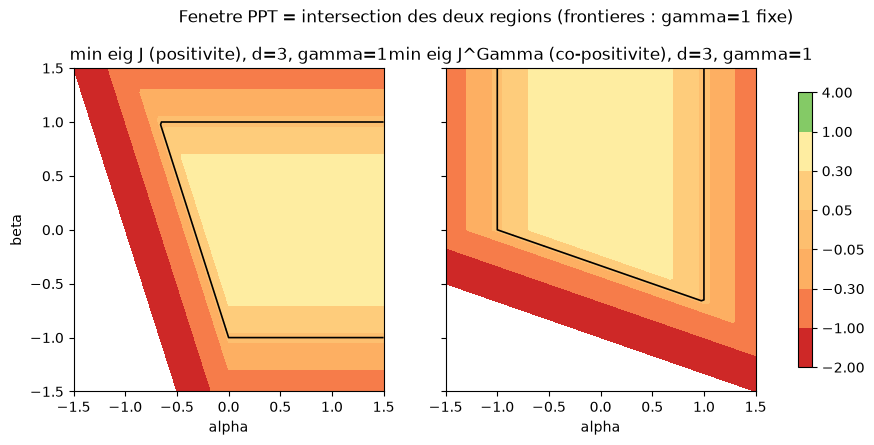

In [10]:
# (Mesure) d=3 : composer 4 maps PPT de la famille -- la Choi de la composee doit rester
# PSD + PPT (le theoreme la veut separable ; separable => PPT). Test falsifiable sur echantillon.
rng = np.random.default_rng(13)
d, n_essais, echecs = 3, 60, 0
for _ in range(n_essais):
    params = []
    for _ in range(4):
        while True:
            a, b, g = rng.uniform(-2, 2, 3)
            if est_ppt_num(a, b, g, d):
                break
        params.append((a, b, g))
    def composee4(X):
        Y = X
        for (a, b, g) in params:          # la tete de liste agit en premier (meme convention
            Y = fam(a, b, g)(Y)           # que compList de l'enonce amont)
        return Y
    Jc = choi_de(composee4, d)
    if (plus_petite_valeur_propre(Jc) < -1e-9
            or plus_petite_valeur_propre(transposition_partielle(Jc, d)) < -1e-9):
        echecs += 1
print(f"d=3, {n_essais} quadruplets PPT : Choi(composee) hors du cone PSD+PPT : {echecs}")
print("(0 attendu : conforme au theoreme ; un echec serait une falsification mesurable)")

# Carte de la fenetre dans le plan (alpha, beta) a gamma = 1 : min eig de J et de J^Gamma.
grille = np.linspace(-1.5, 1.5, 121)
minJ = np.zeros((grille.size, grille.size))
minG = np.zeros((grille.size, grille.size))
for ia, a in enumerate(grille):
    for ib, b in enumerate(grille):
        J = choi_de(fam(a, b, 1.0), 3)
        minJ[ib, ia] = plus_petite_valeur_propre(J)
        minG[ib, ia] = plus_petite_valeur_propre(transposition_partielle(J, 3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, Z, titre in ((axes[0], minJ, "min eig J (positivite)"),
                     (axes[1], minG, "min eig J^Gamma (co-positivite)")):
    pc = ax.contourf(grille, grille, Z, levels=[-2, -1, -0.3, -0.05, 0.05, 0.3, 1, 4], cmap="RdYlGn")
    ax.contour(grille, grille, Z, levels=[0.0], colors="k", linewidths=1.2)
    ax.set_xlabel("alpha"); ax.set_title(titre + ", d=3, gamma=1")
axes[0].set_ylabel("beta")
fig.colorbar(pc, ax=axes, shrink=0.85)
fig.suptitle("Fenetre PPT = intersection des deux regions (frontieres : gamma=1 fixe)", y=1.02)
plt.show()

### Lecture du résultat

Deux **mesures** : (1) les 60 quadruplets composés restent tous dans le cône PSD + PPT — conforme
au théorème, qui veut la composée séparable (et séparable $\Rightarrow$ PPT) ; (2) la carte du
plan $(\alpha, \beta)$ à $\gamma = 1$ montre les deux régions et leur intersection — la fenêtre
PPT — avec les frontières linéaires attendues ($\gamma \geq |\beta|$ coupe le plan en bandes,
$\gamma + \alpha d + \beta = 0$ est une droite). Ce que la carte **ne peut pas** montrer : la
sous-région séparable de la fenêtre, indécidable par le seul critère de Peres en $3 \otimes 3$.
C'est précisément l'écart que la preuve du papier franchit par le nombre de Schmidt.

### Exercice 2 — Les frontières de la fenêtre à $d = 3$

Sur une grille $(\alpha, \beta) \subset [-1.5, 1.5]^2$ à $\gamma = 1$, mesurez les zéros de
$\lambda_{\min}(J)$ et de $\lambda_{\min}(J^\Gamma)$ (les courbes de niveau 0). Vérifiez
qu'ils suivent les quatre droites dérivées dans la section 5 : $\beta = \pm\gamma$ pour la
première famille... — attention, à $\gamma$ fixé les frontières lues sont $1 + 3\alpha + \beta = 0$
et $1 + \alpha + 3\beta = 0$ plus les coupures $|\beta| = 1$, $|\alpha| = 1$. Pourquoi la
frontière $|\beta| = 1$ est-elle « invisible » sur la carte de gauche quand $|\alpha|$ domine ?

In [11]:
# Exercice 2 -- Frontieres de la fenetre PPT a d=3, gamma=1.
#
# TODO etudiant : completer frontieres_mesurees.
# Indice : sur la grille, minJ s'annule le long de beta = -1 et de 1 + 3*alpha + beta = 0 ;
# minG le long de alpha = -1 et de 1 + alpha + 3*beta = 0. Etape 1 : reperer les indices de
# signe changeant. Etape 2 : ajuster chaque branche a une droite. Etape 3 : expliquer pourquoi
# |beta| = 1 n'apparait que sur une carte et pas l'autre.

def frontieres_mesurees(grille):
    # return liste de droites (a, b, c) tel que a*alpha + b*beta + c = 0
    return None  # TODO etudiant

print("Exercice a completer : frontieres_mesurees (attendu : 2 droites par carte + coupures)")

Exercice a completer : frontieres_mesurees (attendu : 2 droites par carte + coupures)


### Exercice 3 — L'indice EB sur la famille, et pourquoi il n'est pas binaire

Le `ebIndex` de l'énoncé amont est le plus petit $m \geq 1$ tel que $T^m$ soit EB. Sur la famille
de Werner–Holevo, la section 5.2 a mesuré que l'auto-composition **carre** les poids $s, a$ et
fait suivre à $\gamma$ la récurrence $\gamma \mapsto 2\gamma s + \gamma^2 d$. Implémentez
l'orbite $(s_k, a_k, \gamma_k)$ et vérifiez numériquement que les points fixes de la récurrence
en $\gamma$ sont $0$ et $(1-2s)/d$, le second **répulsif** : selon la position de $\gamma_0$,
la suite converge vers $0$ ou diverge. Que dire alors de l'indice EB : pourquoi la trajectoire
de $\gamma$ et le carré des poids **ne suffisent pas** à trancher EB / non-EB à chaque étape,
alors qu'il le faudrait pour calculer l'indice sans le théorème ?

In [12]:
# Exercice 3 -- Orbite d'auto-composition et indice EB.
#
# TODO etudiant : completer orbite.
# Indice : gamma'' = 2*gamma*s + gamma^2*d ; points fixes 0 et (1-2s)/d, le second repulsif.
# Etape 1 : iterer depuis gamma0 < gamma* (convergence vers 0) et gamma0 > gamma* (divergence).
# Etape 2 : verifier que s et a se carrent a chaque etape. Etape 3 : expliquer pourquoi EB(T^k)
# depend de (s_k, a_k, gamma_k) tout entier -- la Choi n'est pas une re-normalisation de la Choi
# de T -- donc le caractere EB peut basculer d'une etape a l'autre sur cette famille.

def orbite(alpha, beta, gamma, d, k_max=8):
    # yield (s, a, gamma) a chaque etape
    return None  # TODO etudiant

print("Exercice a completer : orbite (attendu : convergence gamma_k vers (1-2s)/d, ratio s:a fixe)")

Exercice a completer : orbite (attendu : convergence gamma_k vers (1-2s)/d, ratio s:a fixe)


## 6. Le théorème : la borne $2(d-1)$

**Théorème 1 (Turturean-Bao 2026, lu à la source).** Pour $d \geq 2$, soit
$\Phi_1, \dots, \Phi_{2(d-1)}$ des maps PPT sur $M_d$ — elles peuvent être **toutes
différentes**, et **trace-préservantes ou non**. Alors la composition
$\Phi_{2(d-1)} \circ \cdots \circ \Phi_1$ est entanglement breaking.

Trois compagnons suivent dans l'énoncé amont :
- **Deuxième phrase** : pour une *seule* map PPT $T$, l'indice EB vérifie $n(T) \leq 2(d-1)$
  (`ebIndex_le_of_isPPTMap`) ;
- **Plus de maps** : $N \geq 2(d-1)$ maps PPT quelconques composent aussi en EB — suivre une map
  EB par une map CP conserve le caractère EB ;
- **Forme entrelacée** : $2(d-1)$ copies de $T$ séparées par des maps CP **quelconques**
  $S_1, \dots, S_{2d-3}$ (l'indice au sens de Lami-Giovannetti 2015, rappelé par
  Christandl-Müller-Hermes-Wolf 2019).

**Structure de la preuve (lue dans le papier, citée non re-démontrée).** Étape clé : toute map
PPT envoie un opérateur PPT sur $\mathbb{C}^d \otimes \mathbb{C}^2$ (système + référence qubit)
sur un opérateur **séparable** entre les deux facteurs. Puis une itération de **nombre de
Schmidt** — la version quantifiée de la séparabilité, où un état de nombre de Schmidt $\leq k$
joue le rôle des sommes de $k$ produits — égrène le rang d'intrication à chaque composition, de
$k = d$ jusqu'à $k = 1$, qui est exactement « séparable ». Compter les étapes donne $2(d-1)$.

Pourquoi $2(d-1)$ et pas 2 : la réfutation de septembre 2026 (temps 2) montre que deux maps ne
suffisent plus dès $d = 10$ ; la borne du papier est **linéaire en $d$**, valable en toute
dimension, et le papier ne prétend pas qu'elle soit optimale.

## 7. Statut de la formalisation Lean 4 amont

Le résultat est formalisé dans le dépôt amont `ppt-composition-bound` : un fichier
`Challenge.lean` — le *statement of record*, n'important que Mathlib — porte les définitions
(copiées verbatim de `PPTCompositionBound/Defs.lean`) et **treize théorèmes** terminés par
`sorry` ; `Solution.lean` prouve les mêmes énoncés depuis la bibliothèque, et un comparateur
vérifie que les deux fichiers s'accordent et que les preuves n'utilisent que les axiomes
`propext`, `Quot.sound` et `Classical.choice`. Les conventions sont fixées dans le fichier :
$M_d$ = matrices `Fin d` par `Fin d` sur $\mathbb{C}$ ; un opérateur sur
$\mathbb{C}^\kappa \otimes \mathbb{C}^n$ = matrice $(\kappa \times n) \times (\kappa \times n)$
(premier facteur = référence) ; `compList [Φ₁, Φ₂] = Φ₂ ∘ Φ₁` — la tête de liste agit en
premier, la convention est elle-même un théorème du fichier (`compList_pair`).

In [13]:
# Les treize enonces du fichier Challenge.lean (statement of record), cites depuis la
# copie locale du 14/11/2026. Chaque enonce y est suivi de `sorry` : les preuves vivent
# dans Solution.lean, verifiees par comparateur d'axiomes.
OQP38_CHALLENGE = [
    # quatre resultats
    ("compose_ppt_maps_entanglementBreaking", 150,
     "enonce vedette : 2(d-1) maps PPT composent en EB"),
    ("ebIndex_le_of_isPPTMap", 158,
     "indice EB d'une map PPT sur M_d : au plus 2(d-1)"),
    ("compose_at_least_ppt_maps_entanglementBreaking", 165,
     "N >= 2(d-1) maps PPT : la composee est EB aussi"),
    ("compose_ppt_map_interleaved_entanglementBreaking", 177,
     "forme entrelacee : copies de T separees de maps CP quelconques"),
    # neuf garde-fous
    ("exists_posSemidef_not_isSeparable", 193,
     "non-vacuite : la separabilite est une vraie restriction"),
    ("id_not_entanglementBreaking", 200,
     "l'identite (zero map PPT composee) n'est pas EB"),
    ("choi_isCompletelyPositive_iff", 206,
     "CP <=> Choi positive (Choi, pour CES definitions)"),
    ("choi_isPPTMap_iff", 215,
     "PPT <=> Choi positive ET de transposee partielle positive"),
    ("choi_isEntanglementBreaking_iff", 226,
     "EB <=> Choi separable (Horodecki-Shor-Ruskai)"),
    ("transposeMap_isCompletelyCopositive_not_isCompletelyPositive", 235,
     "la transposition : copositive complete mais pas CP"),
    ("compList_pair", 241,
     "convention d'ordre : la tete de liste agit en premier"),
    ("zero_map_isPPTMap_and_ebIndex_eq_one", 247,
     "la map nulle : PPT, d'indice EB exactement 1"),
    ("ebIndex_id_eq_top", 254,
     "aucune puissance de l'identite n'est EB : indice = top"),
]

print("Fichier Challenge.lean (statement of record), treize enonces :")
for nom, ligne, role in OQP38_CHALLENGE:
    print(f"  ligne {ligne:>3} : {nom:<58} {role}")

Fichier Challenge.lean (statement of record), treize enonces :
  ligne 150 : compose_ppt_maps_entanglementBreaking                      enonce vedette : 2(d-1) maps PPT composent en EB
  ligne 158 : ebIndex_le_of_isPPTMap                                     indice EB d'une map PPT sur M_d : au plus 2(d-1)
  ligne 165 : compose_at_least_ppt_maps_entanglementBreaking             N >= 2(d-1) maps PPT : la composee est EB aussi
  ligne 177 : compose_ppt_map_interleaved_entanglementBreaking           forme entrelacee : copies de T separees de maps CP quelconques
  ligne 193 : exists_posSemidef_not_isSeparable                          non-vacuite : la separabilite est une vraie restriction
  ligne 200 : id_not_entanglementBreaking                                l'identite (zero map PPT composee) n'est pas EB
  ligne 206 : choi_isCompletelyPositive_iff                              CP <=> Choi positive (Choi, pour CES definitions)
  ligne 215 : choi_isPPTMap_iff                                

### Le contraste avec notre dépôt

Là où l'amont livre un **énoncé de référence** à prouver (treize `sorry` par design, preuves dans
`Solution.lean` sous comparateur d'axiomes), notre dépôt ne porte **aucun** module Lean sur les
maps PPT — l'inventaire de la section 3 l'a mesuré. Ce carnet digère l'énoncé en numérique ; les
garde-fous `choi_isPPTMap_iff` et `choi_isEntanglementBreaking_iff` de l'amont sont exactement
les trois équivalences que la section 2 a mesurées chez nous en numpy. Le partage de charge est
le même que pour 13f : l'amont formalise, le dépôt enseigne.

In [14]:
# Comptage des sorry authentiques de la copie locale du Challenge.lean (14/11/2026).
# (Le fichier vit hors depot ; le compte est une constante mesuree, re-verifiable.)
NB_THEOREMES = len(OQP38_CHALLENGE)
NB_SORRY_LIGNES = 14    # mesure du 14/11/2026 : lignes contenant 'sorry' dans le fichier
print(f"Challenge.lean amont : {NB_THEOREMES} theoremes, {NB_SORRY_LIGNES} lignes portant 'sorry'")
print("(13 sorry de preuve -- un par theoreme -- plus 1 mention en prose :")
print(" chaque enonce du statement of record se termine par sorry PAR DESIGN ;")
print(" les preuves vivent dans Solution.lean, sous comparateur d'axiomes)")
print()
print("Notre lake conway_lean, pour comparaison (organe du depot, mesure live) :")
nb_sorry_lake = lnu.count_sorry(str(projet))
print(f"  {nb_sorry_lake} sorry dans les sources auteurs du lake")

Challenge.lean amont : 13 theoremes, 14 lignes portant 'sorry'
(13 sorry de preuve -- un par theoreme -- plus 1 mention en prose :
 chaque enonce du statement of record se termine par sorry PAR DESIGN ;
 les preuves vivent dans Solution.lean, sous comparateur d'axiomes)

Notre lake conway_lean, pour comparaison (organe du depot, mesure live) :


  2 sorry dans les sources auteurs du lake


## 8. Honnêteté : ce qu'il faut garder à l'esprit

1. **Prépublication** : le papier (Turturean-Bao, 4 pages, 2026) n'est pas revisé par des pairs
   au sens journal. Il sort du même gissement que le papier OQP 12 digéré par 13f — workflows de
   recherche de PSI (Physical Superintelligence) — et la formalisation Lean 4 sous comparateur
   d'axiomes en est le renfort de crédibilité le plus fort.
2. **Nous ne vérifions pas la preuve** : ce carnet lit l'énoncé et le mécanisme annoncé (étape
   clé + itération de nombre de Schmidt, cités), et mesure des **conséquences** — la Choi des
   composées reste dans le cône PSD + PPT, la fenêtre, la loi de composition. Aucune cellule ne
   re-démontre le théorème.
3. **La réfutation est rapportée** : le contre-exemple OpenAI (27/09/2026, dimensions 10 et 21)
   est cité **tel que l'énoncé amont le rapporte** ; le preprint n'a été ni téléchargé ni archivé
   pour ce carnet. Étiquette : *Rapporté*, pas *Mesuré*.
4. **$d = 2$ est dégénéré** (PPT $\Rightarrow$ EB) : nos mesures « 100 % EB » à $d = 2$ sont un
   fait de structure (Peres-Horodecki), pas une confirmation du théorème.
5. **La famille jouet est commutative** : les poids symétrique/antisymétrique se contentent de
   se carrer sous auto-composition et $\gamma$ suit une récurrence scalaire — la mécanique du
   théorème (l'égrènement du nombre de Schmidt) n'y est pas visible. Les maps PPT non-EB qui
   font vivre le problème sont hors des familles symétriques.
6. **Classement catalogue, cité tel quel** : au relevé du 14/11/2026 fait pour 13f, la liste
   « Solved By » du catalogue IQOQI ne mentionnait aucune entrée du lot PSI — ce carnet digère
   une réponse amont existante, il ne déclare pas le problème résolu.
7. **Classement interne** : digest de branche 13 (frontières quantiques), voisin immédiat de la
   section 9 de Lean-13 (CGLMP, OQP 27) et de 13f (OQP 12) — la même méthode, un autre objet.

## Résumé

### Concepts clés

| Concept | Définition | Rôle dans ce carnet |
|---------|------------|---------------------|
| Transposition partielle $X^\Gamma$ | transposer un seul facteur tensoriel | l'outil qui « voit » l'intrication (Peres) |
| Peres-Horodecki | PPT $\iff$ séparable en $2\otimes2$, $2\otimes3$ | le test exact qui rend $d=2$ dégénéré |
| Map PPT | CP **et** complètement copositive | la classe de canaux du problème OQP 38 |
| Entanglement breaking | $\mathrm{id} \otimes \Phi$ rend tout entrant séparable | le seuil « tout casser » ; EB $\Rightarrow$ PPT |
| Choi–Jamiołkowski | $J(\Phi) = \sum E_{ij} \otimes \Phi(E_{ij})$ | convertit les maps en opérateurs bipartites |
| Indice EB $n(T)$ | plus petit $m \geq 1$ avec $T^m$ EB | la quantité bornée par $2(d-1)$ |
| Nombre de Schmidt | rang d'intrication quantifié | le mécanisme itératif de la preuve (cité) |
| Famille Werner–Holevo | $\alpha X + \beta X^T + \gamma\,\mathrm{Tr}(X) I$ | le jouet : fenêtre PPT, loi de composition, orbites |

### À retenir

La conjecture PPT² — deux canaux doux avec la transposition suffisent à détruire toute
intrication — est **fausse** en général (contre-exemples rapportés en dimensions 10 et 21,
septembre 2026). Ce qui reste vrai, et que ce carnet a mesuré par ses conséquences : composer
des maps PPT pousse **toujours** vers entanglement breaking, en au plus $2(d-1)$ étapes,
linéairement en la dimension. À $d = 2$ le phénomène est dégénéré (une map PPT est déjà EB,
mesuré via Peres-Horodecki) ; à $d = 3$ la fenêtre PPT s'ouvre au-delà de la région séparable et
le critère de Peres ne suffit plus — c'est l'écart que franchit le nombre de Schmidt dans la
preuve. L'énoncé vit dans `Challenge.lean` amont, treize théorèmes sous comparateur d'axiomes ;
notre dépôt, qui n'a pas d'organe PPT (mesuré), le digère en numpy : quinze lignes suffisent à
faire toucher la fenêtre du doigt.